## LangGraph migration for collect_energy

In [2]:
from __future__ import annotations

import argparse
import json
import time
from pathlib import Path
from typing import Any, Dict, List, Tuple

import numpy as np

In [3]:
from lib.datagen.dynamics import Replica, run_forward_dynamics
from lib.datagen.graph import make_lattice_J, sample_J_num_edges_symmetric
from lib.datagen.utils import make_gemini_pi, make_mock_pi, make_openai_pi, \
                    make_together_pi, make_aihubmix_pi, make_openrouter_pi

/home/lowen/miniconda3/envs/poa/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/lowen/miniconda3/envs/poa/lib/python3.9/site-packages/google/auth/__init__.py:54: FutureWarning: You are using a Python version 3.9 past its end of life. Google will update google-auth with critical bug fixes on a best-effort basis, but not with any other fixes or features. Please upgrade your Python version, and then update google-auth.
  warnings.warn(eol_message.format("3.9"), FutureWarning)
/home/lowen/miniconda3/envs/poa/lib/python3.9/site-packages/google/oauth2/__init__.py:40: FutureWarning: You are using a Python version 3.9 past its end of life. Google will update google-auth with critical bug fixes on a best-effort basis, but not with any other fixes or features. Please upgrade your Python version, and then upd

In [4]:
from IPython.display import Image, display
import operator
from typing import Annotated, List, Literal, TypedDict
from langgraph.graph import END, START, StateGraph
from langgraph.types import Command, interrupt

/home/lowen/miniconda3/envs/poa/lib/python3.9/site-packages/langgraph/cache/base/__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


In [5]:
class State(TypedDict):
    """State of the workflow."""
    replicas: Annotated[List[str], operator.add]
    step: int
    num_steps: int

In [6]:
def init_node(state: State) -> State:
    """Initialize the workflow state."""
    return {
        'replicas': [],
        'step': 0,
        }

In [7]:
def initial_spins_node(state: State) -> State:
    """First collection of spins."""
    return {
        'replicas': [f"initial spins phase"],
    }

In [8]:
def message_node(state: State) -> dict:
    """Message exchange between agents."""
    step = state['step'] + 1

    return {
        'replicas': [f"message phase {step}"],
        'step': step,
    }

In [9]:
def spins_node(state: State) -> dict:
    """Spin update of the agents."""
    return {
        'replicas': [f"spin phase {state['step']}"],
    }

In [10]:
def save_node(state: State) -> dict:
    """Save the state of the workflow."""
    return {
        'replicas': [f"save phase {state['step']}"],
    }

In [19]:
def branch_initial_spins(state: State) -> Literal['save', 'message']:
    """Branching function"""
    if state['num_steps'] == 0:
        return 'save'
    else: 
        return 'message'

In [ ]:
def loop_steps(state: State) -> Literal['message', END]:
    """Routing function to determine if we should continue or end the workflow."""
    if state['step'] < state['num_steps']:
        return "message"
    else:
        return END

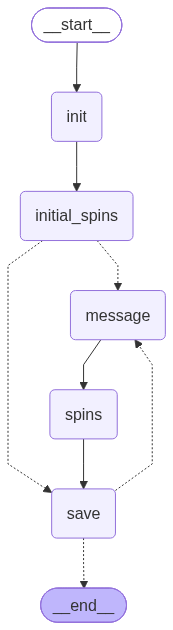

In [20]:
builder = StateGraph(State)

# Add nodes
builder.add_node('init', init_node)
builder.add_node('initial_spins', initial_spins_node)
builder.add_node('message', message_node)
builder.add_node('spins', spins_node)
builder.add_node('save', save_node)

# Add edges
builder.add_edge(START, 'init')
builder.add_edge('init', 'initial_spins')
builder.add_conditional_edges('initial_spins', branch_initial_spins)
builder.add_edge('message', 'spins')
builder.add_edge('spins', 'save')
builder.add_conditional_edges('save', loop_steps)

# Compile and display
graph = builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

In [13]:
graph.invoke({'num_steps': 3})

{'replicas': ['message phase 1',
  'spin phase 1',
  'save phase 1',
  'message phase 2',
  'spin phase 2',
  'save phase 2',
  'message phase 3',
  'spin phase 3',
  'save phase 3'],
 'step': 3,
 'num_steps': 3}